# Preliminary Analysis of  Data

**Objective:** Explore FTIR data from rat lung tissues across different treatment durations. I preprocess the data, reduce dimensionality, perform clustering, and visualize the results to identify patterns related to treatment effects.

**Treatment Groups:**
- Control
- 7 Days Treatment
- 14 Days Treatment
- 21 Days Treatment
- 28 Days Treatment

**Challenges:**
- Large data files (~500x1500x500 arrays).
- No annotations.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from specml.data.spectroscopic_data import SpectroscopicData
import specml.processing.masking as masking
import logging
import os
# Turn off logging
logging.basicConfig(level=logging.CRITICAL)
logger = logging.getLogger(__name__)
logger.setLevel(logging.CRITICAL)
logging.getLogger('specml').setLevel(logging.CRITICAL)


## Step 1: Data Loading - Define paths to treatment group labels


In [2]:
import os
import re
# Mapping of group numbers to treatment durations
group_mapping = {
    '1': 'Control',
    '2': '28 Days',
    '4': '21 Days',
    '6': '14 Days',
    '8': '7 Days'
}
data_dir = 'D:/Lung_Data_8cm/'

file_paths = []
treatment_groups = []

# Loop over the top-level folders
for folder_name in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder_name)
    if os.path.isdir(folder_path):
        # Extract the group number before 'F' using a regular expression
        match = re.match(r'(\d+)F', folder_name)
        if match:
            group_number = match.group(1)
            treatment = group_mapping.get(group_number)
            if treatment is None:
                print(f"Warning: Group number {group_number} in folder {folder_name} not recognized.")
                continue
        else:
            print(f"Warning: Folder name {folder_name} does not match expected pattern.")
            continue

        # Traverse the subfolders within the top-level folder
        for subfolder_name in os.listdir(folder_path):
            subfolder_path = os.path.join(folder_path, subfolder_name)
            if os.path.isdir(subfolder_path):
                # Look for .dmt files in the subfolder
                for file_name in os.listdir(subfolder_path):
                    if file_name.endswith('.dmt'):
                        file_path = os.path.join(subfolder_path, file_name)
                        file_paths.append(file_path)
                        treatment_groups.append(treatment)


In [3]:
print(treatment_groups)

['Control', 'Control', 'Control', 'Control', 'Control', 'Control', '28 Days', '28 Days', '28 Days', '28 Days', '28 Days', '28 Days', '14 Days', '14 Days', '14 Days', '14 Days', '7 Days', '7 Days', '7 Days', '7 Days', '7 Days', '7 Days', '21 Days', '21 Days', '21 Days', '21 Days', '21 Days', 'Control', 'Control', 'Control', '28 Days', '28 Days', '28 Days', '28 Days', '28 Days', '28 Days', '28 Days', '28 Days', '28 Days']


## Step 2. Data Preprocessing
#### Data is large, we need to process 1 sample at a time

In [4]:
# Wavenumber range of interest - let's take only fingerprint region: 1000 to 1800 cm^-1 
lower_wavenumber = 1000
upper_wavenumber = 1800

# Set preprocessing flags
apply_baseline_correction = False 
apply_deriv = False  
area_threshold = 2.0
denoising_method = 'None'

In [5]:
# Preprocessing steps:
# 1. Keep range 950-3550 cm^-1
# 2. Remove CO2 region and wax artifacts
# 3. apply mask over amide 1 auc (1600-1700 cm^-1)
# 4. Denoising (PCA/MNF/golay smoothing) [optional] 
# 4. apply baseline correction - for now linear (min_to_zero) but in future we can add polynomial
# 5. normalize the spectra (vector normalization)
# 6. derivative (if needed)
# 7. keep some specific wavenumbers (1000-1800 cm^-1)
import specml.processing.preprocessing as preprocessing

def preprocess_sample(spec_data):
    """
    Preprocesses a SpectroscopicData sample.
    """
    # Keep the wavenumber range of interest
    spec_data.keep_range(3550, 950)
    # Remove CO2 and wax regions
    spec_data.remove_co2()
    spec_data.remove_wax()

    area = spec_data.calculate_area(1600,1700)
    tissue_mask = masking.create_mask_from_area(area=area, threshold=area_threshold)
    spec_data.data = masking.apply_mask(spec_data.data, tissue_mask)
    spec_data.mask = masking.rebuild_tissue_mask(spec_data, tissue_mask)

    # Denoising (optional)
    if denoising_method == 'pca':
        spec_data.data = preprocessing.pca_denoising(spec_data.data, n_components=10)
    elif denoising_method == 'mnf':
        spec_data.data = preprocessing.mnf_denoising(spec_data.data, n_components=10)
    elif denoising_method == 'golay':
        # Apply Savitzky-Golay smoothing
        spec_data.data, new_wavenumbers = preprocessing.apply_savitzky_golay(
            spec_data.data,
            wavenumbers=spec_data.wavenumbers,
            window_length=11,
            polyorder=2,
            deriv=0
        )
        spec_data.wavenumbers = new_wavenumbers
    else:
        # No denoising applied
        pass

    # Baseline correction
    from specml.processing.preprocessing import adjust_spectra_min_to_zero
    spec_data.data = adjust_spectra_min_to_zero(spec_data.data)

    # Normalize the spectra
    spec_data.normalize(method='vector')

    # Smoothing (if applicable)
    if apply_deriv:
        spec_data.apply_derivative(window_length=23, polyorder=3, deriv=2)

    # spec_data.keep_range(1800, 1000)
    return spec_data


import sys

def get_size(obj, seen=None):
    """Recursively finds the size of objects."""
    size = sys.getsizeof(obj)
    if seen is None:
        seen = set()
    obj_id = id(obj)
    if obj_id in seen:
        return 0
    # Mark as seen
    seen.add(obj_id)
    if isinstance(obj, dict):
        size += sum([get_size(v, seen) for v in obj.values()])
        size += sum([get_size(k, seen) for k in obj.keys()])
    elif hasattr(obj, '__dict__'):
        size += get_size(obj.__dict__, seen)
    elif hasattr(obj, '__iter__') and not isinstance(obj, (str, bytes, bytearray)):
        size += sum([get_size(i, seen) for i in obj])
    return size


In [6]:
import sys
print(len(file_paths))
total_memory = 0
total_mask = 0
spectroscopic_data_objects = []

for i in range(0,len(file_paths)):
    print(file_paths[i])
    spec_data = SpectroscopicData(file_paths[i])
    spec_data = preprocess_sample(spec_data)
    spectroscopic_data_objects.append(spec_data)
    label = treatment_groups[i]
    spec_data.labels = np.array([label] * spec_data.data.shape[0])
    data_memory = sys.getsizeof(spec_data.data)
    mask_memory = sys.getsizeof(spec_data.mask)
    total_memory += data_memory
    total_mask += mask_memory

    total_size = get_size(spec_data)
    print(f"Total size of spec_data object: {total_size / (1024 ** 3):.2f} GB")

print(f"Total memory used (GB): {total_memory / (1024 ** 3):.6f} GB")
print(f"Total memory used for masks (GB): {total_mask / (1024 ** 3):.6f} GB")

39
D:/Lung_Data_8cm/1F-1504-01\1F-1504-01_top\1f-1504-01_top.dmt
Total size of spec_data object: 0.61 GB
D:/Lung_Data_8cm/1F-1504-01\1F-1504-01_top2\1f-1504-01_top2.dmt
Total size of spec_data object: 0.63 GB
D:/Lung_Data_8cm/1F-1504-01\1F-1504-01_bot\1f-1504-01_bot.dmt
Total size of spec_data object: 0.56 GB
D:/Lung_Data_8cm/1F-1504-01\1F-1504-01_bot2\1f-1504-01_bot2.dmt
Total size of spec_data object: 0.29 GB
D:/Lung_Data_8cm/1F-1504-01\1F-1504-01_mid\1f-1504-01_mid.dmt
Total size of spec_data object: 0.15 GB
D:/Lung_Data_8cm/1F-1504-01\1F-1504-01_mid2\1f-1504-01_mid2.dmt
Total size of spec_data object: 0.43 GB
D:/Lung_Data_8cm/2F-2501-01\1F-2501-01_bot2\1f-2501-01_bot2.dmt
Total size of spec_data object: 0.54 GB
D:/Lung_Data_8cm/2F-2501-01\1F-2501-01_mid\1f-2501-01_mid.dmt
Total size of spec_data object: 0.55 GB
D:/Lung_Data_8cm/2F-2501-01\1F-2501-01_mid2\1f-2501-01_mid2.dmt
Total size of spec_data object: 0.41 GB
D:/Lung_Data_8cm/2F-2501-01\1F-2501-01_top\1f-2501-01_top.dmt
Total s

## Step 3. Display some tissues for processing

Data is flattened. Reshaping it back to 3D.
Image slice shape: (512, 1024)


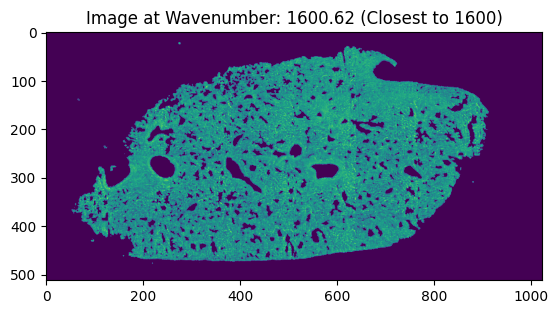

Data is flattened. Reshaping it back to 3D.
Image slice shape: (768, 1024)


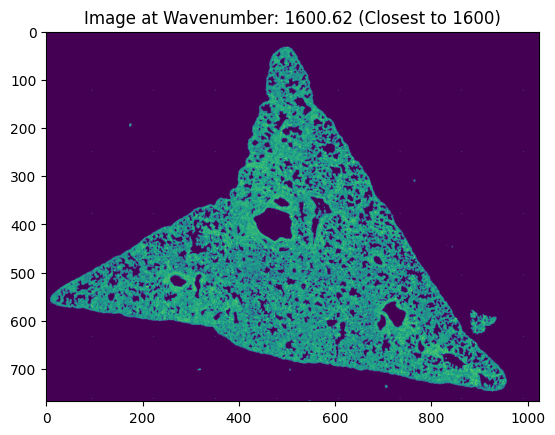

Data is flattened. Reshaping it back to 3D.
Image slice shape: (384, 1152)


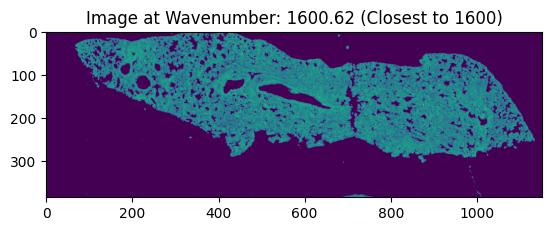

Data is flattened. Reshaping it back to 3D.
Image slice shape: (512, 1408)


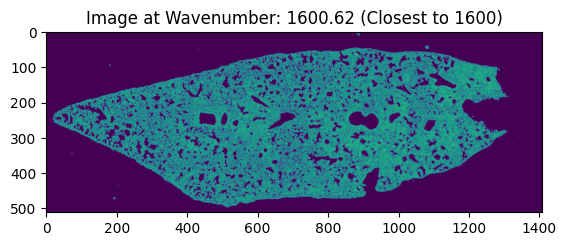

Data is flattened. Reshaping it back to 3D.
Image slice shape: (384, 896)


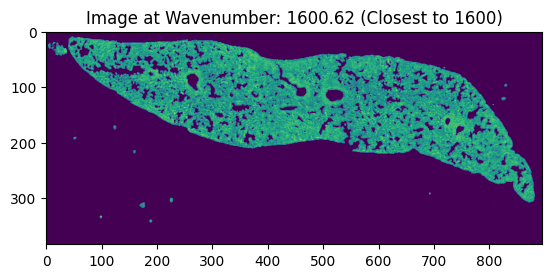

In [7]:
from specml.visualization.plotting import plot_image_over_wavenumber
import random
# Display the image over wavenumber 1600 for every group from group_mapping
target_wavenumber = 1600

for group in group_mapping.values():
    indices = [i for i, x in enumerate(treatment_groups) if x == group]
    if indices:
        random_index = random.choice(indices)
        spec_data_obj = spectroscopic_data_objects[random_index]
        plot_image_over_wavenumber(spec_data_obj, target_wavenumber=target_wavenumber)

## Combine, Perform PCA and plot

c:\Users\u37314kd\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ValueError: 'c' argument must be a color, a sequence of colors, or a sequence of numbers, not array(['Control', 'Control', 'Control', ..., '28 Days', '28 Days',
       '28 Days'], dtype='<U7')

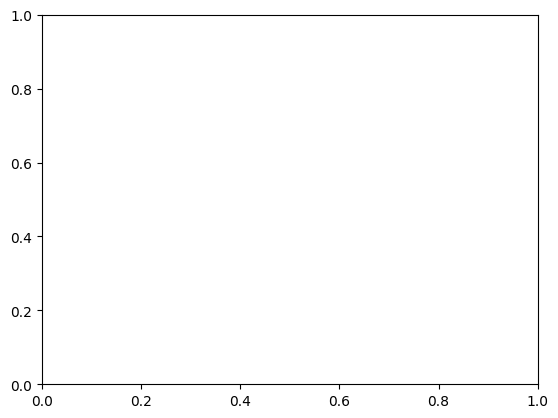

In [8]:
from specml.feature_engineering.dim_reduction import apply_pca
from specml.visualization.plotting import plot_dim_reduction_result

combined_data = SpectroscopicData()
combined_data.data = np.concatenate([spec_data.data for spec_data in spectroscopic_data_objects])
combined_data.labels = np.concatenate([spec_data.labels for spec_data in spectroscopic_data_objects])
combined_data.mask = np.concatenate([spec_data.mask for spec_data in spectroscopic_data_objects])
combined_data.wavenumbers = spectroscopic_data_objects[0].wavenumbers
combined_data.file_paths = [spec_data.file_path for spec_data in spectroscopic_data_objects]


pca_res = apply_pca(combined_data, n_components=2)

plot_dim_reduction_result(pca_res, combined_data.labels, title='PCA')

[4 4 4 ... 2 2 2]


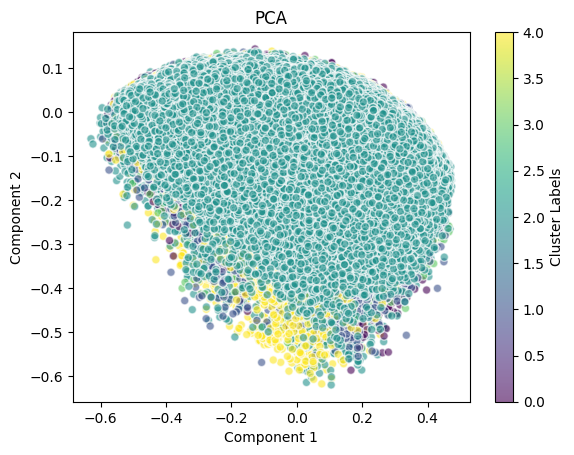

In [ ]:
from matplotlib import cm
from sklearn.preprocessing import LabelEncoder

# Encode the labels to integers
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(combined_data.labels)

print(encoded_labels)

# Get unique colors for each label
unique_labels = np.unique(encoded_labels)
colors = cm.rainbow(np.linspace(0, 1, len(unique_labels)))

# Create a color map
color_map = {label: colors[i] for i, label in enumerate(unique_labels)}

# Map the colors to the encoded labels
label_colors = np.array([color_map[label] for label in encoded_labels])

plot_dim_reduction_result(pca_res, labels=encoded_labels, title='PCA')

In [ ]:
print(pca_res.reduced_data.shape)

{0: array([0.5, 0. , 1. , 1. ]), 1: array([0.00196078, 0.70928131, 0.92328911, 1.        ]), 2: array([0.50392157, 0.99998103, 0.70492555, 1.        ]), 3: array([1.        , 0.70054304, 0.37841105, 1.        ]), 4: array([1.0000000e+00, 1.2246468e-16, 6.1232340e-17, 1.0000000e+00])}
